<a href="https://colab.research.google.com/github/muhammadbinasim33-ui/Business-Data-Text-Mining-Assignments/blob/main/BA3002_Assignment1_i234600_Muhammad_Bin_Asim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BA3002 — Assignment 1
## QuickCart Data Acquisition, Cleaning & Integration Challenge

**Student Name:** Muhammad Bin Asim   
**Roll No.:** 23I-4600
**Section:** BSBA(A)

> Complete each section. Add short Markdown explanations for every important cleaning decision. AI tools are allowed, but you must understand and be able to explain your work.

## Part A — Setup and Load the Data
Import the required libraries and load `quickcart_raw.csv` and `quickcart_products.csv`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# TODO: Import libraries
import pandas as pd
import requests
from bs4 import BeautifulSoup
import numpy as np
import json
# TODO: Load datasets
raw = pd.read_csv('/content/drive/MyDrive/quickcart_raw.csv')
products = pd.read_csv('/content/drive/MyDrive/quickcart_products.csv')

## Part B — Initial Data Audit
Inspect shape, columns, data types, missing values, duplicates, descriptive statistics, and suspicious values.

In [ ]:
# TODO: Perform an initial data-quality audit
#1 Shape:
print("Dataset shape:",raw.shape)
#2. column names:
print("Column names",raw.columns.tolist())
#3 Datatypes:
print("Data types",raw.dtypes)
#4. Missing values:
print("Missing values:",raw.isnull().sum())
#5. Discriptive stats:
print("Discriptive stats:",raw.info())
#6. Duplicate records:
print("Duplicate records:", raw.duplicated().sum())

Dataset shape: (155, 13)
Column names ['Order_ID', 'Customer_ID', 'Product_ID', 'City', 'Order_Date', 'Delivery_Date', 'Quantity', 'Unit_Price', 'Discount_Pct', 'Rating', 'Returned', 'Payment_Method', 'Review']
Data types Order_ID           object
Customer_ID        object
Product_ID         object
City               object
Order_Date         object
Delivery_Date      object
Quantity            int64
Unit_Price        float64
Discount_Pct        int64
Rating            float64
Returned           object
Payment_Method     object
Review             object
dtype: object
Missing values: Order_ID          0
Customer_ID       0
Product_ID        0
City              4
Order_Date        0
Delivery_Date     0
Quantity          0
Unit_Price        2
Discount_Pct      0
Rating            3
Returned          0
Payment_Method    0
Review            2
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 13 columns):
 #   Column          Non-Null Co

Row Check For City Column


In [ ]:
# Checking rows with missing cities
print("Rows with missing cities")
display(raw[raw['City'].isnull()])

Rows with missing cities


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review
4,O1005,C152,P107,NaN,2026-03-10,2026-03-11,4,3900.0,10,3.6,No,Cash,Delivery was acceptable.
33,O1034,C115,P102,NaN,2026-02-05,2026-02-13,1,6100.0,5,3.2,No,Easypaisa,Product was okay for the price.
74,O1075,C121,P102,NaN,2026-03-31,2026-04-01,2,5750.0,15,3.7,No,Cash,Delivery was acceptable.
121,O1122,C128,P101,NaN,2026-03-10,2026-03-12,4,2350.0,0,4.7,No,Cash,Good quality and reasonable price.


Checking whether city can be replaced on the basis of customer id

In [ ]:
# Customer check:
missing_city_customers = raw.loc[raw['City'].isnull(), 'Customer_ID']

raw[raw['Customer_ID'].isin(missing_city_customers)][
    ['Order_ID', 'Customer_ID', 'City']
].sort_values('Customer_ID')

,Order_ID,Customer_ID,City
33,O1034,C115,NaN
115,O1116,C115,KHI
120,O1121,C115,ISB
14,O1015,C121,Lahore
74,O1075,C121,NaN
76,O1077,C121,Peshawar
130,O1131,C121,Lahore
132,O1133,C121,islamabad
35,O1036,C128,Rawalpindi
75,O1076,C128,Peshawar


## Exact row check

In [ ]:
raw[raw['Unit_Price'].isnull()]

,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review
17,O1018,C138,P107,Karachi,2026-07-11,2026-07-16,1,NaN,15,3.2,No,CARD,Works as expected.
98,O1099,C112,P105,Islamabad,2026-05-05,2026-05-13,1,NaN,5,2.8,No,wallet,Works as expected.


Unit price of product check

In [ ]:
missing_price_products = raw.loc[raw['Unit_Price'].isnull(), 'Product_ID']

raw[raw['Product_ID'].isin(missing_price_products)][
    ['Order_ID', 'Product_ID', 'Unit_Price']
].sort_values('Product_ID')

,Order_ID,Product_ID,Unit_Price
11,O1012,P105,5000.0
130,O1131,P105,4400.0
98,O1099,P105,NaN
20,O1021,P105,4750.0
93,O1094,P105,4950.0
81,O1082,P105,4350.0
80,O1081,P105,4850.0
41,O1042,P105,4750.0
44,O1045,P105,4900.0
68,O1069,P105,4750.0


## Product Master Check

In [ ]:
products[products['Product_ID'].isin(['P105', 'P107'])]

,Product_ID,Product_Name,Category,Standard_Price,Supplier
4,P105,USB-C Hub,Accessories,4800,ConnectPro
6,P107,Laptop Stand,Accessories,3900,DeskEase


Missing reviews

In [ ]:
print("Rows with missing reviews")
display(raw[raw['Review'].isnull()])

Rows with missing reviews


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review
21,O1022,C152,P101,RWP,2026-07-13,2026-07-21,4,2650.0,5,2.0,Yes,Card,NaN
85,O1086,C144,P101,PEW,2026-05-22,2026-05-23,3,2450.0,10,3.6,No,easypaisa,NaN


Missing ratings

In [ ]:
print("rows with Missing ratings ")
display(raw[raw['Rating'].isnull()])

rows with Missing ratings 


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review
8,O1009,C109,P103,Rawalpindi,2026-06-15,2026-06-23,4,8450.0,20,NaN,Yes,Card,Product is fine but nothing special.
52,O1053,C134,P106,Karachi,2026-01-21,2026-01-24,1,18900.0,5,NaN,No,wallet,Packaging was good and delivery was on time.
110,O1111,C116,P107,KHI,2026-03-11,2026-03-14,2,3900.0,10,NaN,Yes,Wallet,Delivery was acceptable.


# **Missing City Investigation:**
### Four records were found with missing values in the city column. The corresponding customer records were investiogated to determine whether the missing cities could be recovered using other orders. However the customers had multiple different cities across their orders. Therefore assigning the city on the bases of customer_id would not be reliable, and the cities should not be guessed. So in cleaning the city column we are adderessing the missing cities as Unknown.
# **Unit Price:**
Two missing Unit_Price values were identified for products P105 and P107. The product master was checked and provided Standard_Price values of 4,800 for P105 and 3,900 for P107. These reference prices provide a reliable basis for addressing the missing values. The audit also identified a Unit_Price of 650,000 for P107, which is substantially higher than the other observed prices, and a negative Unit_Price of -4,200, which is invalid. These values require further investigation before treatment.
# **Missing Review Investigation:**
Two records were found with missing values in the Review column: O1022 and O1086. Since reviews are customer-specific textual responses and there is no reliable reference from which the original review can be recovered, the missing reviews will not be guessed or replaced with existing review text.
#**Missing Rating Investigation:**
Three records were identified with missing values in the Rating column. The missing ratings cannot be reliably reconstructed from the available fields because a rating represents customer-specific feedback. Therefore, no rating will be guessed or assigned based on the product, customer, or return status. Thus in cleaning process i will keep it as missing, pandas will automatically delete them.

## Part C — Data Cleaning
Clean the raw dataset. For each major change, explain **what you changed and why** in a Markdown cell.

In [ ]:
# Creating copy of the original raw dataset:
clean_raw = raw.copy()
print("Raw dataset shape",raw.shape)
print("Clean raw shape:",clean_raw.shape)


Raw dataset shape (155, 13)
Clean raw shape: (155, 13)


#**Remove Exact Duplicate Records**

Five exact duplicate records were identified during the data quality audit. Since these records contain the same information as existing records, they would incorrectly increase order counts and could affect analysis. Therefore, the exact duplicate records are removed from the cleaned dataset.

In [ ]:
# TODO: Clean missing, duplicate, inconsistent, invalid, and suspicious values
duplicates_before = clean_raw.duplicated().sum()

clean_df = clean_raw.drop_duplicates().copy()

duplicates_after = clean_df.duplicated().sum()

print("Duplicate records before cleaning:", duplicates_before)
print("Duplicate records after cleaning:", duplicates_after)
print("Shape after removing duplicates:", clean_df.shape)

Duplicate records before cleaning: 5
Duplicate records after cleaning: 0
Shape after removing duplicates: (150, 13)


## VALIDATION:

In [ ]:
print("Remaining duplicate records:", clean_df.duplicated().sum())

Remaining duplicate records: 0


#Handle Missing City Values

Four records had missing values in the City column. The corresponding customers were investigated using their other orders, but the same customers appeared with different cities. Therefore, assigning a city based on Customer_ID would not be reliable.

The missing city values are therefore replaced with "Unknown" rather than guessing a location. This preserves the records while clearly indicating that the original city information was unavailable.

In [ ]:
city_missing_before = clean_df['City'].isna().sum()

clean_df['City'] = clean_df['City'].fillna('Unknown')

city_missing_after = clean_df['City'].isna().sum()

print("Missing City values before:", city_missing_before)
print("Missing City values after:", city_missing_after)

Missing City values before: 4
Missing City values after: 0


# Validation

In [ ]:
print(clean_df['City'].value_counts(dropna=False))

City
Peshawar       15
rawalpindi     12
Rawalpindi     12
Karachi        10
 Lahore        10
karachi         9
peshawar        9
RWP             8
PEW             8
LHR             8
Karachi         7
ISB             7
Lahore          7
lahore          6
KHI             6
islamabad       4
 Islamabad      4
Unknown         4
Islamabad       4
Name: count, dtype: int64


## **Standardize City Labels.**
The City column contains inconsistent text representations, including differences in capitalization and abbreviations. These variations can cause the same city to be counted as different categories during analysis.
City labels are standardized to consistent full city names. Whitespace is also removed.

In [ ]:
clean_df ['City'] = clean_df['City'].astype(str).str.strip()
city_mapping = {'KHI': 'Karachi',
    'khi': 'Karachi',
    'Karachi': 'Karachi',
     'karachi': 'Karachi',
    'ISB': 'Islamabad',
    'isb': 'Islamabad',
    'islamabad': 'Islamabad',
    'Islamabad': 'Islamabad',
    'Lahore': 'Lahore',
    'lahore': 'Lahore',
    'RWP': 'Rawalpindi',
    'rwp': 'Rawalpindi',
    'Rawalpindi': 'Rawalpindi',
     'rawalpindi': 'Rawalpindi',
    'PEW': 'Peshawar',
    'pew': 'Peshawar',
    'peshawar': 'Peshawar',
    'Peshawar': 'Peshawar',
    'Unknown': 'Unknown',
    'LHR': 'Lahore'
}
clean_df['City'] = clean_df['City'].replace(city_mapping)

VALIDATION

In [ ]:
print(clean_df['City'].value_counts())

City
Rawalpindi    32
Peshawar      32
Karachi       32
Lahore        31
Islamabad     19
Unknown        4
Name: count, dtype: int64


# **Handle Missing Unit Price**

Two records had missing values in Unit_Price. The corresponding Product_ID values were checked against the product master. Product P105 has a standard price of 4,800 and product P107 has a standard price of 3,900.

These product master prices provide a reasonable reference for the missing values, so they are used instead of removing the affected orders.

In [ ]:
# Check missing prices before treatment
print("Missing Unit_Price before:", clean_df['Unit_Price'].isna().sum())

# Get standard prices from product master
price_lookup = products.set_index('Product_ID')['Standard_Price']

# Fill missing prices using Product_ID
clean_df['Unit_Price'] = clean_df['Unit_Price'].fillna(
    clean_df['Product_ID'].map(price_lookup)
)

print("Missing Unit_Price after:", clean_df['Unit_Price'].isna().sum())

Missing Unit_Price before: 2
Missing Unit_Price after: 0


# Validation

In [ ]:
print(
    clean_df[clean_df['Order_ID'].isin(['O1099', 'O1018'])][
        ['Order_ID', 'Product_ID', 'Unit_Price']
    ]
)

   Order_ID Product_ID  Unit_Price
17    O1018       P107      3900.0
98    O1099       P105      4800.0


# **Handle Invalid Negative Unit Price**
## One record contained a negative Unit_Price of -4,200 for Product P107. A negative selling price is not logically valid for this dataset.

## The product master was checked and P107 has a Standard_Price of 3,900. Therefore, the invalid negative value is replaced with the product master reference price of 3,900 rather than deleting the entire order.

In [ ]:
negative_price_mask = clean_df['Unit_Price'] < 0

print("Negative Unit_Price values before:", negative_price_mask.sum())

clean_df.loc[negative_price_mask, 'Unit_Price'] = (
    clean_df.loc[negative_price_mask, 'Product_ID'].map(price_lookup)
)

print(
    "Negative Unit_Price values after:",
    (clean_df['Unit_Price'] < 0).sum()
)

Negative Unit_Price values before: 1
Negative Unit_Price values after: 0


VALIDATION

In [ ]:
print(
  clean_df[clean_df['Unit_Price'] < 0][
        ['Order_ID', 'Product_ID', 'Unit_Price']
    ]
)

Empty DataFrame
Columns: [Order_ID, Product_ID, Unit_Price]
Index: []


##**Handling the Suspicious outlier value of P107**
As we can see in the inspection part of this assignment that there is a data entry issue in P107. The value of 650,000 does not match the standard price in Product master range for P107. We can niether use triming or capping methods to handle this, but we can replace the value with the standard price in the Products csv that is 3900.

In [ ]:
outlier_mask = clean_df['Unit_Price'] == 650000

print("650000 values before:", outlier_mask.sum())

clean_df.loc[outlier_mask, 'Unit_Price'] = (
    clean_df.loc[outlier_mask, 'Product_ID'].map(price_lookup)
)

print(
    "650000 values after:",
    (clean_df['Unit_Price'] == 650000).sum()
)

650000 values before: 1
650000 values after: 0


Validation

In [ ]:
print(
    clean_df[clean_df['Order_ID'] == 'O1065'][
        ['Order_ID', 'Product_ID', 'Unit_Price']
    ]
)

   Order_ID Product_ID  Unit_Price
64    O1065       P107      3900.0


**Handle Missing Review Values**

Two records have missing values in the Review column. Reviews are customer-specific textual responses and cannot be reliably reconstructed from the available Product_ID, Customer_ID, Rating, or Return information.

Therefore, the missing reviews are labelled "No Review" instead of guessing or copying another customer's review.

In [ ]:
review_missing_before = clean_df['Review'].isna().sum()

clean_df['Review'] = clean_df['Review'].fillna('No Review')

review_missing_after = clean_df['Review'].isna().sum()

print("Missing Review values before:", review_missing_before)
print("Missing Review values after:", review_missing_after)

Missing Review values before: 2
Missing Review values after: 0


**Handle Missing Rating Values**

Three records have missing values in the Rating column. A rating represents individual customer feedback and cannot be reliably reconstructed from the product, customer, return status, or review.

Therefore, the missing rating values are retained as missing (NaN) rather than assigning an artificial value. Keeping them missing preserves the fact that no rating was provided and avoids introducing unsupported assumptions into the analysis.

In [ ]:
print("Missing Rating values:", clean_df['Rating'].isna().sum())

Missing Rating values: 3


**Standardize Returned Values**

The Returned field represents a categorical Yes/No response. Text formatting is standardized by removing whitespace and converting values to a consistent Yes/No format.

In [ ]:
clean_df['Returned'] = (
    clean_df['Returned']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'yes': 'Yes',
        'no': 'No'
    })
)

VALIDATION

In [ ]:
print(clean_df['Returned'].value_counts(dropna=False))

Returned
No     119
Yes     31
Name: count, dtype: int64


**Standardized Payment Method**
Inspection

In [ ]:
print(clean_df['Payment_Method'].value_counts(dropna=False))

Payment_Method
Cash         20
cash         19
card         18
Easypaisa    18
Card         17
easypaisa    16
Wallet       15
wallet       14
CARD         13
Name: count, dtype: int64


**Standardize Payment Method:**
The Payment_Method field is categorical, so inconsistent capitalization or whitespace can result in the same payment method being treated as different categories. The values are standardized to a consistent format.

In [ ]:
clean_df['Payment_Method'] = (
    clean_df['Payment_Method']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'card': 'Card',
        'cash': 'Cash',
        'easypaisa': 'Easypaisa',
        'wallet': 'Wallet'
    })
)

Validation

In [ ]:
print(clean_df['Payment_Method'].value_counts(dropna=False))

Payment_Method
Card         48
Cash         39
Easypaisa    34
Wallet       29
Name: count, dtype: int64


Standardizing Dates Columns

In [ ]:
clean_df['Order_Date'] = pd.to_datetime(
    clean_df['Order_Date'],
    errors='coerce'
)

clean_df['Delivery_Date'] = pd.to_datetime(
    clean_df['Delivery_Date'],
    errors='coerce'
)

print(clean_df[['Order_Date', 'Delivery_Date']].dtypes)

Order_Date       datetime64[ns]
Delivery_Date    datetime64[ns]
dtype: object


**Validate Date Consistency:**

The cleaned date fields are checked to ensure that delivery dates are not earlier than order dates. Records violating this logical relationship would require investigation.

In [ ]:
invalid_dates = clean_df[
    clean_df['Delivery_Date'] < clean_df['Order_Date']
]

print("Records with Delivery_Date before Order_Date:", len(invalid_dates))

invalid_dates[
    ['Order_ID', 'Order_Date', 'Delivery_Date']
]

Records with Delivery_Date before Order_Date: 1


,Order_ID,Order_Date,Delivery_Date
47,O1048,2026-02-27,2026-02-25


In [ ]:
clean_df[clean_df['Order_ID'] == 'O1048'].T


,47
Order_ID,O1048
Customer_ID,C124
Product_ID,P112
City,Karachi
Order_Date,2026-02-27 00:00:00
Delivery_Date,2026-02-25 00:00:00
Quantity,2
Unit_Price,5350.0
Discount_Pct,0
Rating,2.9


In [ ]:
customer_id = clean_df.loc[
    clean_df['Order_ID'] == 'O1048', 'Customer_ID'
].iloc[0]

clean_df[clean_df['Customer_ID'] == customer_id][
    ['Order_ID', 'Customer_ID', 'Order_Date', 'Delivery_Date']
].sort_values('Order_Date')

,Order_ID,Customer_ID,Order_Date,Delivery_Date
47,O1048,C124,2026-02-27,2026-02-25


Changing the date

In [ ]:
clean_df.loc[
    clean_df['Order_ID'] == 'O1048',
    'Delivery_Date'
] = pd.NaT

Validation

In [ ]:
invalid_dates = clean_df[
    clean_df['Delivery_Date'] < clean_df['Order_Date']
]

print("Records with Delivery_Date before Order_Date:", len(invalid_dates))

Records with Delivery_Date before Order_Date: 0


**Validate Numeric Ranges**

Numeric fields are checked against their expected logical ranges. Quantity and Unit_Price should not be negative, Discount_Pct should be between 0 and 100, and Rating should be within the expected 1–5 rating scale.

In [ ]:
print("Negative Quantity:", (clean_df['Quantity'] < 0).sum())
print("Negative Unit_Price:", (clean_df['Unit_Price'] < 0).sum())

print(
    "Invalid Discount_Pct:",
    ((clean_df['Discount_Pct'] < 0) |
     (clean_df['Discount_Pct'] > 100)).sum()
)

print(
    "Invalid Rating:",
    ((clean_df['Rating'] < 1) |
     (clean_df['Rating'] > 5)).sum()
)

Negative Quantity: 1
Negative Unit_Price: 0
Invalid Discount_Pct: 2
Invalid Rating: 2


In [ ]:
# Investigate all invalid numeric values

print("Negative Quantity:")
display(
    clean_df[clean_df['Quantity'] < 0][
        ['Order_ID', 'Product_ID', 'Quantity']
    ]
)

print("\nInvalid Discount_Pct:")
display(
    clean_df[
        (clean_df['Discount_Pct'] < 0) |
        (clean_df['Discount_Pct'] > 100)
    ][
        ['Order_ID', 'Product_ID', 'Discount_Pct']
    ]
)

print("\nInvalid Rating:")
display(
    clean_df[
        (clean_df['Rating'] < 1) |
        (clean_df['Rating'] > 5)
    ][
        ['Order_ID', 'Product_ID', 'Rating']
    ]
)

Negative Quantity:


,Order_ID,Product_ID,Quantity
119,O1120,P108,-2



Invalid Discount_Pct:


,Order_ID,Product_ID,Discount_Pct
56,O1057,P104,135
132,O1133,P112,-10



Invalid Rating:


,Order_ID,Product_ID,Rating
36,O1037,P111,9.5
101,O1102,P106,0.0


In [ ]:
# C14 — Handle invalid numeric values

# Negative Quantity: -2 → 1
clean_df.loc[
    clean_df['Order_ID'] == 'O1120',
    'Quantity'
] = 1

# Discount_Pct: 135% → 100%
clean_df.loc[
    clean_df['Order_ID'] == 'O1057',
    'Discount_Pct'
] = 100

# Discount_Pct: -10% → 0%
clean_df.loc[
    clean_df['Order_ID'] == 'O1133',
    'Discount_Pct'
] = 0

# Rating: 9.5 → 5
clean_df.loc[
    clean_df['Order_ID'] == 'O1037',
    'Rating'
] = 5

# Rating: 0 → 1
clean_df.loc[
    clean_df['Order_ID'] == 'O1102',
    'Rating'
] = 1

# Validation
print("Negative Quantity:",
      (clean_df['Quantity'] < 0).sum())

print("Invalid Discount_Pct:",
      ((clean_df['Discount_Pct'] < 0) |
       (clean_df['Discount_Pct'] > 100)).sum())

print("Invalid Rating:",
      ((clean_df['Rating'] < 1) |
       (clean_df['Rating'] > 5)).sum())

Negative Quantity: 0
Invalid Discount_Pct: 0
Invalid Rating: 0


**Remove Unnecessary Whitespace:**
Leading and trailing whitespace is removed from text fields to ensure that identical categories are not treated as different values during analysis.

In [ ]:
text_columns = [
    'Order_ID',
    'Customer_ID',
    'Product_ID',
    'City',
    'Returned',
    'Payment_Method',
    'Review'
]

for col in text_columns:
    clean_df[col] = clean_df[col].astype(str).str.strip()

print("Whitespace cleaning completed.")

Whitespace cleaning completed.


**Standardize Categorical Values**

Categorical fields are standardized to ensure consistent capitalization and naming. This prevents the same category from being counted separately due to differences in text formatting.

In [ ]:
# Standardize Returned
clean_df['Returned'] = (
    clean_df['Returned']
    .str.strip()
    .str.lower()
    .replace({
        'yes': 'Yes',
        'no': 'No'
    })
)

# Standardize Payment Method
clean_df['Payment_Method'] = (
    clean_df['Payment_Method']
    .str.strip()
    .str.lower()
    .replace({
        'card': 'Card',
        'cash': 'Cash',
        'easypaisa': 'Easypaisa',
        'wallet': 'Wallet'
    })
)

print("Returned categories:")
print(clean_df['Returned'].value_counts())

print("\nPayment Method categories:")
print(clean_df['Payment_Method'].value_counts())

Returned categories:
Returned
No     119
Yes     31
Name: count, dtype: int64

Payment Method categories:
Payment_Method
Card         48
Cash         39
Easypaisa    34
Wallet       29
Name: count, dtype: int64


**Verify Data Types**

The cleaned dataset is checked to confirm that numeric fields are numeric, date fields are datetime values, and identifier/categorical fields remain appropriate for analysis.

In [ ]:
print(clean_df.dtypes)

Order_ID                  object
Customer_ID               object
Product_ID                object
City                      object
Order_Date        datetime64[ns]
Delivery_Date     datetime64[ns]
Quantity                   int64
Unit_Price               float64
Discount_Pct               int64
Rating                   float64
Returned                  object
Payment_Method            object
Review                    object
dtype: object


**Verify Duplicate Records**

A final duplicate check is performed to confirm that the exact duplicate records identified during the audit have been removed.

In [ ]:
print(
    "Remaining duplicate records:",
    clean_df.duplicated().sum()
)

Remaining duplicate records: 0


In [ ]:
missing_final = pd.DataFrame({
    'Column': clean_df.columns,
    'Missing_Values': clean_df.isna().sum()
})

missing_final = missing_final[
    missing_final['Missing_Values'] > 0
]

missing_final

,Column,Missing_Values
Order_Date,Order_Date,1
Delivery_Date,Delivery_Date,1
Rating,Rating,3


FINAL NUMERIC VALIDATION

In [ ]:
print("Negative Quantity:", (clean_df['Quantity'] < 0).sum())
print("Negative Unit_Price:", (clean_df['Unit_Price'] < 0).sum())
print("Invalid Discount_Pct:", ((clean_df['Discount_Pct'] < 0) | (clean_df['Discount_Pct'] > 100)).sum())
print("Invalid Rating:", ((clean_df['Rating'] < 1) | (clean_df['Rating'] > 5)).sum())

Negative Quantity: 0
Negative Unit_Price: 0
Invalid Discount_Pct: 0
Invalid Rating: 0


FINAL QUALITY CHECK

In [ ]:
final_quality_check = pd.DataFrame({
    'Check': [
        'Duplicate records',
        'Missing City',
        'Missing Unit_Price',
        'Missing Rating',
        'Missing Review',
        'Negative Quantity',
        'Negative Unit_Price',
        'Invalid Discount_Pct',
        'Invalid Rating',
        'Delivery before Order'
    ],
    'Count': [
        clean_df.duplicated().sum(),
        clean_df['City'].isna().sum(),
        clean_df['Unit_Price'].isna().sum(),
        clean_df['Rating'].isna().sum(),
        clean_df['Review'].isna().sum(),
        (clean_df['Quantity'] < 0).sum(),
        (clean_df['Unit_Price'] < 0).sum(),
        ((clean_df['Discount_Pct'] < 0) | (clean_df['Discount_Pct'] > 100)).sum(),
        ((clean_df['Rating'] < 1) | (clean_df['Rating'] > 5)).sum(),
        (clean_df['Delivery_Date'] < clean_df['Order_Date']).sum()
    ]
})

final_quality_check

,Check,Count
0,Duplicate records,0
1,Missing City,0
2,Missing Unit_Price,0
3,Missing Rating,3
4,Missing Review,0
5,Negative Quantity,0
6,Negative Unit_Price,0
7,Invalid Discount_Pct,0
8,Invalid Rating,0
9,Delivery before Order,0


REVIEW THE CLEAN DATASET

In [ ]:
print("Final dataset dimensions:", clean_df.shape)

display(clean_df.head(10))

clean_df.info()

Final dataset dimensions: (150, 13)


,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review
0,O1001,C112,P106,Rawalpindi,2026-02-03,2026-02-04,3,17900.0,5,3.6,No,Card,Works as expected.
1,O1002,C156,P109,Peshawar,2026-04-16,2026-04-20,3,7450.0,0,3.2,No,Card,Product was okay for the price.
2,O1003,C134,P101,Lahore,2026-02-23,2026-02-24,1,2300.0,0,3.5,No,Card,Product is fine but nothing special.
3,O1004,C130,P102,Karachi,2026-05-04,2026-05-06,4,6700.0,20,4.9,No,Card,Packaging was good and delivery was on time.
4,O1005,C152,P107,Unknown,2026-03-10,2026-03-11,4,3900.0,10,3.6,No,Cash,Delivery was acceptable.
5,O1006,C158,P110,Islamabad,2026-02-22,2026-02-24,1,12950.0,10,3.3,No,Easypaisa,Product is fine but nothing special.
6,O1007,C104,P104,Karachi,2026-07-05,2026-07-09,4,6250.0,5,3.8,Yes,Card,Product was okay for the price.
7,O1008,C117,P110,Lahore,2026-03-07,2026-03-08,2,13650.0,5,3.8,No,Cash,Average experience overall.
8,O1009,C109,P103,Rawalpindi,2026-06-15,2026-06-23,4,8450.0,20,NaN,Yes,Card,Product is fine but nothing special.
9,O1010,C122,P104,Peshawar,2026-05-30,2026-06-01,1,7000.0,10,4.5,No,Card,Excellent product and fast delivery.


<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 0 to 149
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        150 non-null    object        
 1   Customer_ID     150 non-null    object        
 2   Product_ID      150 non-null    object        
 3   City            150 non-null    object        
 4   Order_Date      149 non-null    datetime64[ns]
 5   Delivery_Date   149 non-null    datetime64[ns]
 6   Quantity        150 non-null    int64         
 7   Unit_Price      150 non-null    float64       
 8   Discount_Pct    150 non-null    int64         
 9   Rating          147 non-null    float64       
 10  Returned        150 non-null    object        
 11  Payment_Method  150 non-null    object        
 12  Review          150 non-null    object        
dtypes: datetime64[ns](2), float64(2), int64(2), object(7)
memory usage: 16.4+ KB


SAVED CLEANED DATASET ORDERS

In [ ]:
clean_df.to_csv('cleaned_orders.csv', index=False)

print("Cleaned dataset saved as cleaned_orders.csv")

Cleaned dataset saved as cleaned_orders.csv


## Part D — Data Integration
Merge the cleaned order data with `quickcart_products.csv`. Explain your join choice and check for unmatched records.

## **Selection of Join:**
I selected the left join because i want to keep all the orders even if a product is not found in the Products csv.

In [ ]:
# TODO: Merge datasets and validate the result
merge_df = clean_df.merge(products, on ='Product_ID',how = 'left')
merge_df.head()

,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review,Product_Name,Category,Standard_Price,Supplier
0,O1001,C112,P106,Rawalpindi,2026-02-03,2026-02-04,3,17900.0,5,3.6,No,Card,Works as expected.,Smart Watch,Wearables,18500.0,PulseTech
1,O1002,C156,P109,Peshawar,2026-04-16,2026-04-20,3,7450.0,0,3.2,No,Card,Product was okay for the price.,Webcam HD,Accessories,7600.0,VisionX
2,O1003,C134,P101,Lahore,2026-02-23,2026-02-24,1,2300.0,0,3.5,No,Card,Product is fine but nothing special.,Wireless Mouse,Accessories,2500.0,TechCore
3,O1004,C130,P102,Karachi,2026-05-04,2026-05-06,4,6700.0,20,4.9,No,Card,Packaging was good and delivery was on time.,Mechanical Keyboard,Accessories,6200.0,KeyWorks
4,O1005,C152,P107,Unknown,2026-03-10,2026-03-11,4,3900.0,10,3.6,No,Cash,Delivery was acceptable.,Laptop Stand,Accessories,3900.0,DeskEase


### Unmatched Product ids

In [ ]:
unmatched = merge_df[merge_df['Product_Name'].isna()]
print("Unmatched Product IDs:",len(unmatched))


Unmatched Product IDs: 1


finding which id does not match

In [ ]:
display(
    unmatched[
        ['Order_ID', 'Product_ID']
    ]
)

,Order_ID,Product_ID
137,O1138,P999


In [ ]:
display(
    clean_df[clean_df['Order_ID'] == 'O1138']
)

,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review
137,O1138,C133,P999,Karachi,2026-07-13,2026-07-18,1,9400.0,5,3.5,No,Card,Product was okay for the price.


In [ ]:
display(merge_df[merge_df['Product_ID'] == 'P999']
)

,Order_ID,Customer_ID,Product_ID,City,Order_Date,Delivery_Date,Quantity,Unit_Price,Discount_Pct,Rating,Returned,Payment_Method,Review,Product_Name,Category,Standard_Price,Supplier
137,O1138,C133,P999,Karachi,2026-07-13,2026-07-18,1,9400.0,5,3.5,No,Card,Product was okay for the price.,NaN,NaN,NaN,NaN


**Unmatched Product_ID:** One order (O1138) contained Product_ID P999, which was not found in the products dataset. The order was investigated and retained because its order-level information was complete and usable. Since no reliable product information was available for P999, no product details were manually assigned. A left join was used so that the original order was preserved while the unmatched product fields remained missing.

Final Check FOR D

In [ ]:
print("Orders before merge:", len(clean_df))
print("Rows after merge:", len(merge_df))
print("Unmatched Product_IDs:", merge_df['Product_Name'].isna().sum())

Orders before merge: 150
Rows after merge: 150
Unmatched Product_IDs: 1


## Part E — Feature Preparation and Basic Business Analysis
Create at least **four** useful business features and answer the required business questions.

In [ ]:
# TODO: Create features and perform analysis
##1. Orders by city:
orders_by_city = merge_df['City'].value_counts()
display(orders_by_city)
##2. Orders by Payment method:
orders_by_payment = merge_df['Payment_Method'].value_counts()
##3. Returned vs non returned orders:
orders_returned = merge_df['Returned'].value_counts()
display(orders_returned)
##4. Product Category Performance:
category_performance = (merge_df.groupby('Category')['Quantity'].sum().sort_values(ascending = False))
display(category_performance)

,count
City,
Rawalpindi,32
Peshawar,32
Karachi,32
Lahore,31
Islamabad,19
Unknown,4


,count
Returned,
No,119
Yes,31


,Quantity
Category,
Accessories,166
Audio,62
Mobile Accessories,50
Wearables,47
Gaming,28


Part E (B): Analysis Charts

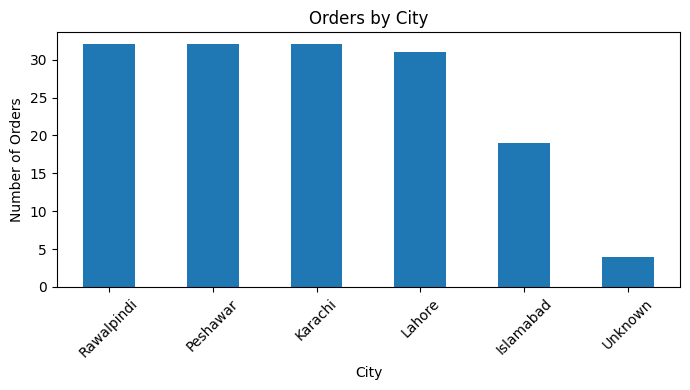

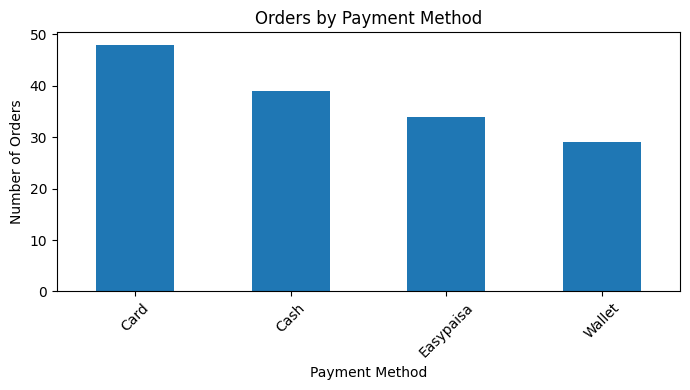

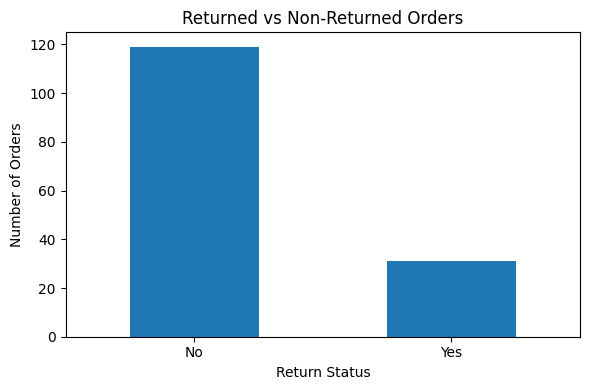

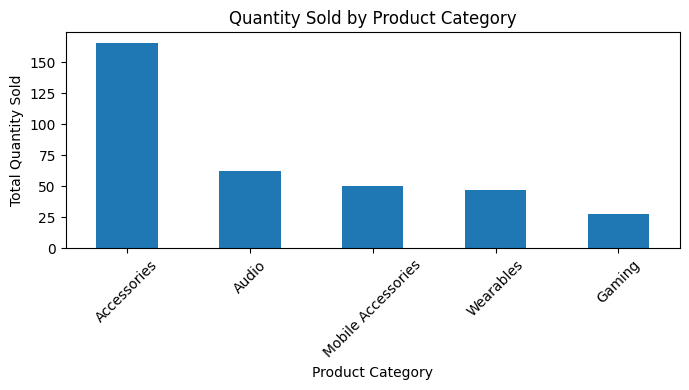

In [ ]:
import matplotlib.pyplot as plt

# 1. Orders by City
plt.figure(figsize=(7, 4))
orders_by_city.plot(kind='bar')
plt.title('Orders by City')
plt.xlabel('City')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Orders by Payment Method
plt.figure(figsize=(7, 4))
orders_by_payment.plot(kind='bar')
plt.title('Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Returned vs Non-Returned Orders
plt.figure(figsize=(6, 4))
orders_returned.plot(kind='bar')
plt.title('Returned vs Non-Returned Orders')
plt.xlabel('Return Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 4. Product Category Performance
plt.figure(figsize=(7, 4))
category_performance.plot(kind='bar')
plt.title('Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Part F — Web Scraping
Collect a small sample of book product data from **Books to Scrape** and save it as `scraped_books.csv`.

Site: https://books.toscrape.com/

Required fields: book title, price, rating.

Web scraping was performed using the requests library to retrieve the webpage and BeautifulSoup to parse its HTML structure. Product titles and prices were extracted from the webpage and stored in a pandas DataFrame. The resulting dataset was inspected to verify that the scraping process successfully collected the required information.

In [ ]:
# TODO: Use requests + BeautifulSoup to collect the required fields
url = "https://books.toscrape.com/"
response = requests.get(url)
print("Status code:",response.status_code)
soup = BeautifulSoup(response.text,'html.parser')

Status code: 200


Inspecting and saving it

In [ ]:
books = []

for book in soup.select('article.product_pod'):
    title = book.h3.a['title']
    price = book.select_one('.price_color').text.strip()
    rating_class = book.select_one('p.star-rating')['class']
    rating = rating_class[1]


    books.append({
        'Title': title,
        'Price': price,
        'Rating':rating
    })

scraped_df = pd.DataFrame(books)

display(scraped_df.head(10))
scraped_df.to_csv('scraped_books.csv', index=False)

print("Scraped book data saved as scraped_books.csv")

,Title,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five
5,The Requiem Red,Â£22.65,One
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,Four
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,Three
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,Four
9,The Black Maria,Â£52.15,One


Scraped book data saved as scraped_books.csv


## Part G — API and JSON
Use JSONPlaceholder to retrieve user data and save it as `api_users.csv`.

API: https://jsonplaceholder.typicode.com/users

A public REST API was accessed using the requests library. The HTTP response status was checked to confirm successful retrieval. The JSON response was then converted into a Python object and inspected to understand its structure and available fields. Finally, the API data was converted into a pandas DataFrame for analysis and saved as a CSV file.

In [ ]:
# TODO: Request JSON data, convert to a DataFrame, inspect it, and save it
api_url = "https://jsonplaceholder.typicode.com/users"
response = requests.get(api_url)
print("Status code:",response.status_code)
soup = BeautifulSoup(response.text,'html.parser')

Status code: 200


Inspecting the response of API

In [ ]:
data = response.json()
print(type(data))
print(data[:5])

<class 'list'>
[{'id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'address': {'street': 'Kulas Light', 'suite': 'Apt. 556', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'geo': {'lat': '-37.3159', 'lng': '81.1496'}}, 'phone': '1-770-736-8031 x56442', 'website': 'hildegard.org', 'company': {'name': 'Romaguera-Crona', 'catchPhrase': 'Multi-layered client-server neural-net', 'bs': 'harness real-time e-markets'}}, {'id': 2, 'name': 'Ervin Howell', 'username': 'Antonette', 'email': 'Shanna@melissa.tv', 'address': {'street': 'Victor Plains', 'suite': 'Suite 879', 'city': 'Wisokyburgh', 'zipcode': '90566-7771', 'geo': {'lat': '-43.9509', 'lng': '-34.4618'}}, 'phone': '010-692-6593 x09125', 'website': 'anastasia.net', 'company': {'name': 'Deckow-Crist', 'catchPhrase': 'Proactive didactic contingency', 'bs': 'synergize scalable supply-chains'}}, {'id': 3, 'name': 'Clementine Bauch', 'username': 'Samantha', 'email': 'Nathan@yesenia.net', 'address': {'street':

Conversion to Data frame

In [ ]:
api_df = pd.DataFrame(data)

display(api_df.head())
print("API dataset dimensions:", api_df.shape)

,id,name,username,email,address,phone,website,company
0,1,Leanne Graham,Bret,Sincere@april.biz,"{'street': 'Kulas Light', 'suite': 'Apt. 556',...",1-770-736-8031 x56442,hildegard.org,"{'name': 'Romaguera-Crona', 'catchPhrase': 'Mu..."
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,"{'street': 'Victor Plains', 'suite': 'Suite 87...",010-692-6593 x09125,anastasia.net,"{'name': 'Deckow-Crist', 'catchPhrase': 'Proac..."
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,"{'street': 'Douglas Extension', 'suite': 'Suit...",1-463-123-4447,ramiro.info,"{'name': 'Romaguera-Jacobson', 'catchPhrase': ..."
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,"{'street': 'Hoeger Mall', 'suite': 'Apt. 692',...",493-170-9623 x156,kale.biz,"{'name': 'Robel-Corkery', 'catchPhrase': 'Mult..."
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,"{'street': 'Skiles Walks', 'suite': 'Suite 351...",(254)954-1289,demarco.info,"{'name': 'Keebler LLC', 'catchPhrase': 'User-c..."


API dataset dimensions: (10, 8)


Saving the file

In [ ]:
api_df.to_csv('api_users.csv', index=False)

print("API data saved as api_users.csv")

API data saved as api_users.csv


## Part H — Executive Summary
Write **200–250 words** covering the major data-quality issues, your most important decisions, and the business value of the cleaned/integrated data.

### Executive Summary

This project focused on acquiring, cleaning, integrating, and analyzing data for the QuickCart dataset using Python in Google Colab. The primary objective was to improve the quality and usability of the provided order data while demonstrating practical data acquisition techniques.

The raw QuickCart order dataset was first inspected to identify data quality issues, including missing values, duplicate records, inconsistent city and payment labels, invalid numeric values, suspicious prices, and inconsistent dates. These issues were investigated before treatment. Duplicate records were removed, city and payment labels were standardized, missing city and review values were handled appropriately, and suspicious unit prices were investigated using the product master dataset. Invalid numeric values and impossible dates were also identified and treated based on the available evidence. The cleaned dataset was then integrated with the product master using Product_ID through a left join. The merge was validated by checking unmatched product IDs and ensuring that the number of order records did not increase unexpectedly.

Basic analysis was performed using four features: orders by city, payment method, return status, and product category performance, with charts created to visualize the results. In addition, web scraping was performed using Requests and BeautifulSoup to collect book titles, prices, and ratings. A public API was also accessed using Requests, and its JSON response was converted into a pandas DataFrame. Overall, the project demonstrated a complete data acquisition, cleaning, integration, and analysis workflow.


## AI Assistance Log
Record meaningful AI assistance. Do not list trivial spelling corrections.

| Prompt / Question | What AI Suggested | Used? | What You Changed / Verified |
|---|---|---|---|
| none | none | none | all done by myself|
| none |none  | none | all done by myself |
| none |  none| none | all done by myself |

## Final Checklist
- [ ✓] Notebook runs from top to bottom
- [ ✓] Cleaning decisions are explained
- [✓ ] Cleaned dataset exported
- [ ✓] Scraped dataset exported
- [✓ ] API dataset exported
- [✓ ] Executive summary completed
- [ ✓] AI Assistance Log completed

Download the Files

In [ ]:
from google.colab import files

files.download('cleaned_orders.csv')
files.download('scraped_books.csv')
files.download('api_users.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>